# 03 — Exploratory analysis

Step 5 of the report: seasonality, autocorrelation, winter episodes, and the link between weather and next-day PM2.5.
Main station: **US Embassy (7441)**, valid days only (≥ 18 h).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plotting import apply_style, save, SERIES, TEXT_2, MODEL_COLORS, SEQ_CMAP
apply_style()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 60)
from preprocessing import aqi_category, AQI_LABELS
d = pd.read_csv(ROOT / "data/processed/station_7441_daily.csv", index_col=0, parse_dates=True)
f = pd.read_csv(ROOT / "data/processed/station_7441_features.csv", index_col=0, parse_dates=True)
pm = d["pm25"]
pm.describe().round(1)

count    2080.0
mean       45.3
std        27.8
min         1.9
25%        25.8
50%        37.6
75%        56.5
max       176.0
Name: pm25, dtype: float64

## 1. The daily series

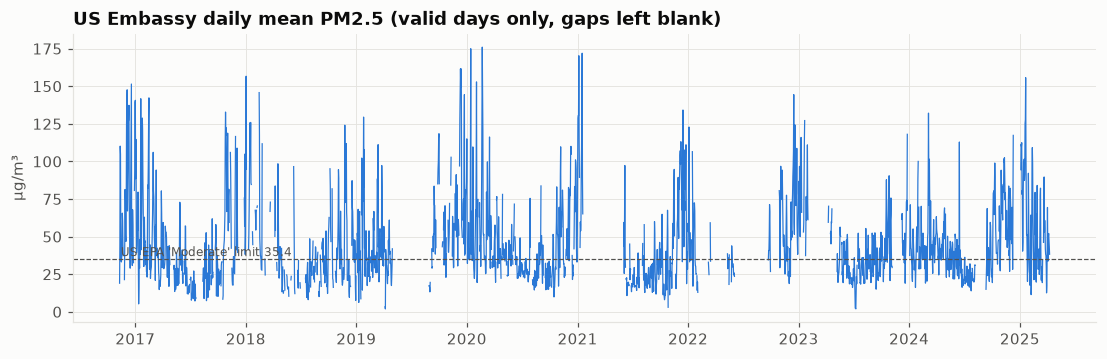

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(pm.index, pm, color=SERIES[0], lw=0.8)   # NaN days break the line, so gaps stay visible
ax.axhline(35.4, color=TEXT_2, lw=0.8, ls="--"); ax.text(pm.index[5], 37, "US EPA 'Moderate' limit 35.4", color=TEXT_2, fontsize=8)
ax.set_ylabel("µg/m³"); ax.set_title("US Embassy daily mean PM2.5 (valid days only, gaps left blank)")
save(fig, "03_daily_series", ROOT)

## 2. Seasonality

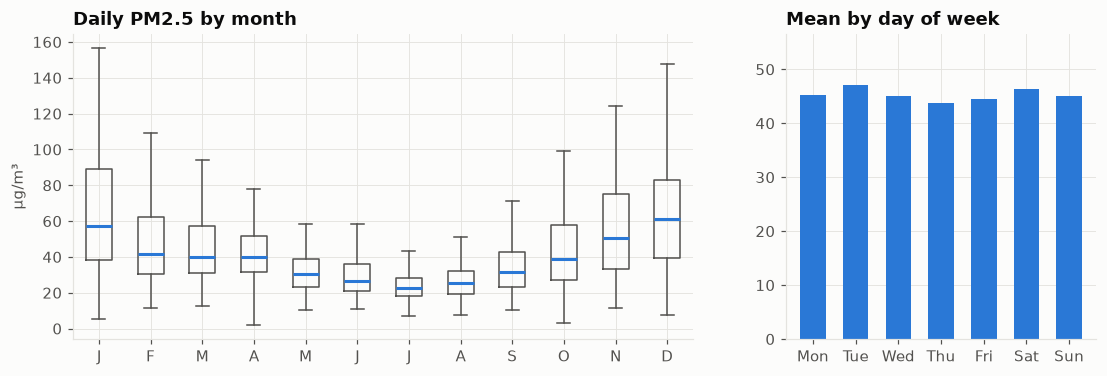

date,1,2,3,4,5,6,7,8,9,10,11,12
mean,65.5,50.3,46.7,42.0,31.7,30.6,23.8,26.8,35.4,44.4,54.7,66.6
median,57.2,41.9,40.1,40.0,30.5,26.3,22.8,25.5,31.6,38.7,50.5,61.1
count,233.0,161.0,167.0,148.0,139.0,152.0,147.0,138.0,181.0,184.0,215.0,215.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
groups = [pm[pm.index.month == m].dropna() for m in range(1, 13)]
axes[0].boxplot(groups, tick_labels=["J","F","M","A","M","J","J","A","S","O","N","D"], showfliers=False,
                medianprops={"color": SERIES[0], "lw": 2}, boxprops={"color": TEXT_2}, whiskerprops={"color": TEXT_2}, capprops={"color": TEXT_2})
axes[0].set_title("Daily PM2.5 by month"); axes[0].set_ylabel("µg/m³")
dow = pm.groupby(pm.index.day_of_week).mean()
axes[1].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dow, color=SERIES[0], width=0.6)
axes[1].set_title("Mean by day of week"); axes[1].set_ylim(0, dow.max() * 1.2)
save(fig, "03_seasonality", ROOT)
pm.groupby(pm.index.month).agg(["mean", "median", "count"]).round(1).T

In [4]:
tet = f["tet_period"] == 1
print(f"Tết period mean PM2.5: {f.loc[tet, 'pm25_lag0'].mean():.1f} µg/m³ vs same months outside Tết: "
      f"{f.loc[~tet & f.month.isin([1, 2]), 'pm25_lag0'].mean():.1f} µg/m³ (n = {f.loc[tet, 'pm25_lag0'].notna().sum()} days)")

Tết period mean PM2.5: 50.6 µg/m³ vs same months outside Tết: 62.3 µg/m³ (n = 103 days)


There is a strong seasonal cycle. December–January means (≈ 66 µg/m³) are almost three times the July mean (≈ 24 µg/m³), because of
thermal inversions, a shallow boundary layer, little rain, and the north-east monsoon bringing air from the Red River delta
and southern China. The day-of-week effect is small. During the Tết period PM2.5 is about 12 µg/m³ lower than on the other January–February days, as traffic and construction stop.

## 3. Autocorrelation

Gaps are not skipped: the correlation at lag k uses only pairs of days that are exactly k calendar days apart.

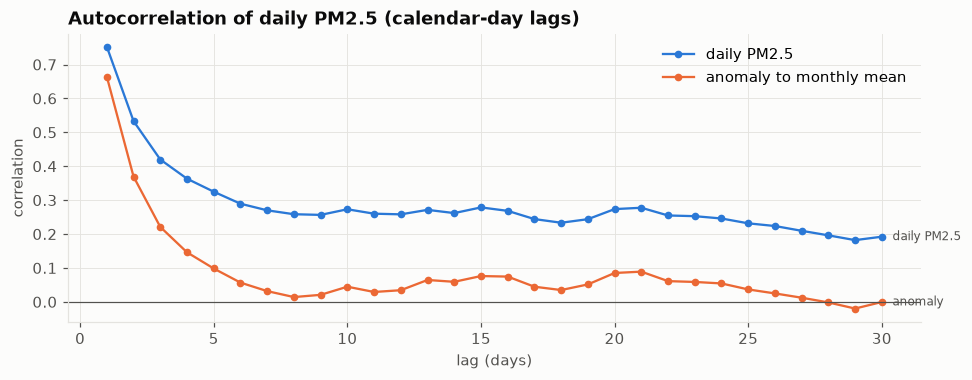

lag-1 r = 0.752 | anomaly lag-1 r = 0.664 | anomaly lag-7 r = 0.032


In [5]:
lags = range(1, 31)
acf = [pm.corr(pm.shift(k)) for k in lags]
anom = pm - pm.groupby(pm.index.month).transform("mean")   # remove seasonal level
acf_anom = [anom.corr(anom.shift(k)) for k in lags]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(lags, acf, marker="o", ms=4, color=SERIES[0], label="daily PM2.5")
ax.plot(lags, acf_anom, marker="o", ms=4, color=SERIES[1], label="anomaly to monthly mean")
ax.text(lags[-1] + 0.4, acf[-1], "daily PM2.5", color=TEXT_2, va="center", fontsize=8)
ax.text(lags[-1] + 0.4, acf_anom[-1], "anomaly", color=TEXT_2, va="center", fontsize=8)
ax.axhline(0, color=TEXT_2, lw=0.8); ax.set_xlabel("lag (days)"); ax.set_ylabel("correlation"); ax.legend()
ax.set_title("Autocorrelation of daily PM2.5 (calendar-day lags)")
save(fig, "03_acf", ROOT)
print("lag-1 r =", round(acf[0], 3), "| anomaly lag-1 r =", round(acf_anom[0], 3), "| anomaly lag-7 r =", round(acf_anom[6], 3))

Yesterday is the best single predictor of today (lag-1 r ≈ 0.75). Once the seasonal level is removed, the memory of the
anomalies fades within about a week, as is typical of synoptic weather episodes (3–7 days). This supports using 7 days of
lags plus the season.

## 4. Winter episodes

In [6]:
w = pm.to_frame("pm25")
w["winter"] = np.where(w.index.month >= 11, w.index.year.astype(str) + "-" + ((w.index.year + 1) % 100).astype(str).str.zfill(2),
                       (w.index.year - 1).astype(str) + "-" + (w.index.year % 100).astype(str).str.zfill(2))
w = w[w.index.month.isin([11, 12, 1, 2, 3])]
episodes = w.groupby("winter")["pm25"].agg(valid_days="count", mean="mean", p90=lambda s: s.quantile(0.9),
                                           days_unhealthy=lambda s: (s > 55.4).sum(), max="max").round(1)
episodes

,valid_days,mean,p90,days_unhealthy,max
winter,,,,,
2016-17,137,60.3,121.3,60,151.5
2017-18,76,65.4,113.7,41,156.7
2018-19,144,44.7,85.4,35,129.5
2019-20,140,63.3,115.1,69,176.0
2020-21,73,67.4,110.0,41,172.0
2021-22,96,55.5,101.9,42,134.2
2022-23,87,66.0,108.2,53,144.4
2023-24,113,46.9,72.7,25,132.1
2024-25,125,59.2,99.4,57,155.7


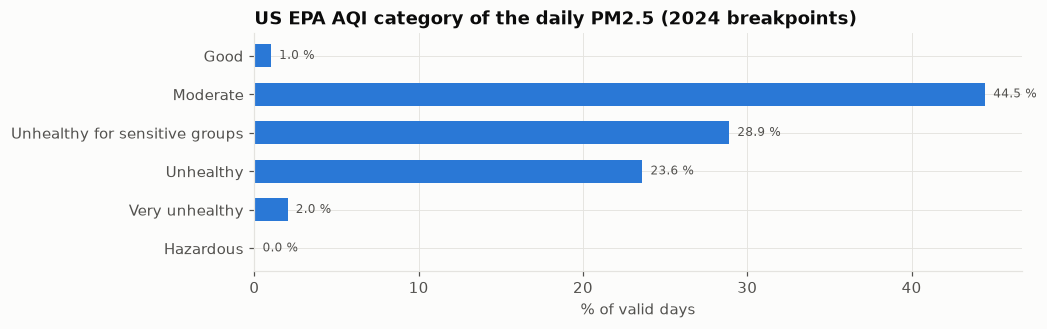

In [7]:
cats = aqi_category(pm.dropna())
share = cats.value_counts(normalize=True).reindex(AQI_LABELS).fillna(0)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(share.index[::-1], share.values[::-1] * 100, color=SERIES[0], height=0.6)
for i, v in enumerate(share.values[::-1] * 100):
    ax.text(v + 0.5, i, f"{v:.1f} %", va="center", color=TEXT_2, fontsize=8)
ax.set_xlabel("% of valid days"); ax.set_title("US EPA AQI category of the daily PM2.5 (2024 breakpoints)")
save(fig, "03_aqi_distribution", ROOT)

## 5. Weather and next-day PM2.5

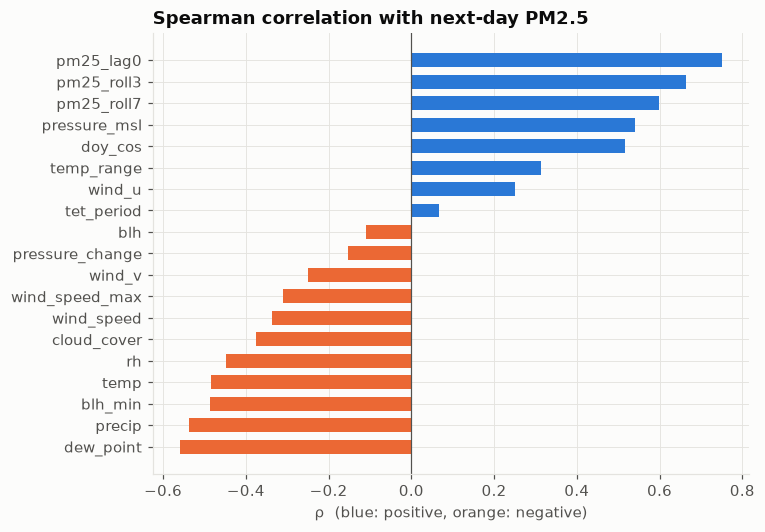

dew_point         -0.560
precip            -0.536
blh_min           -0.487
temp              -0.484
rh                -0.449
cloud_cover       -0.376
wind_speed        -0.337
wind_speed_max    -0.311
wind_v            -0.249
pressure_change   -0.152
blh               -0.110
tet_period         0.066
wind_u             0.250
temp_range         0.314
doy_cos            0.517
pressure_msl       0.540
pm25_roll7         0.599
pm25_roll3         0.664
pm25_lag0          0.752
Name: target, dtype: float64

In [8]:
cand = ["pm25_lag0", "pm25_roll3", "pm25_roll7", "temp", "temp_range", "rh", "dew_point", "precip", "pressure_msl",
        "pressure_change", "wind_speed", "wind_speed_max", "wind_u", "wind_v", "cloud_cover", "blh", "blh_min", "doy_cos", "tet_period"]
sp = f[cand + ["target"]].corr(method="spearman")["target"].drop("target").sort_values()
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(sp.index, sp.values, color=[SERIES[0] if v > 0 else SERIES[1] for v in sp.values], height=0.65)
ax.axvline(0, color=TEXT_2, lw=0.8)
ax.set_title("Spearman correlation with next-day PM2.5"); ax.set_xlabel("ρ  (blue: positive, orange: negative)")
save(fig, "03_feature_correlation", ROOT)
sp.round(3)

**Features kept for modelling.** All PM2.5 lags and rolling statistics (strong persistence). The weather variables that describe
the dispersion conditions: low boundary-layer height, low temperature, high pressure and dry air go with high PM2.5, while
humid air, rain, wind (especially from the south, the summer monsoon) and a high minimum boundary-layer height go with low PM2.5. The seasonal encoding
(day-of-year sin/cos, month) and the Tết flag are also kept. Because several of these variables are collinear (temperature,
dew point, season), the linear model is regularised (Ridge) and the tree models are robust to it.